# Estado del arte: ES semiparamétrica dinámica, retadores neuronales y el marco de prueba retrospectiva comparativa

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los notebooks 04 y 05 de este tema (las pruebas retrospectivas de ES y la comparación de modelos)
- **Tiempo de lectura:** unos 45 minutos

**Pregunta:** ¿Los estimadores más nuevos de VaR y ES, los modelos GAS-FZ y CAViaR-ES, superan a los escalones clásicos de la escalera en seis ventanas de mercado, y concuerda el ajuste GARCH del motor con la implementación de referencia?

## Objetivos

Al terminar este notebook puedes:

- nombrar los métodos académicos actuales para pronosticar VaR y ES juntos, decir qué modela cada uno, y decir cuáles de ellos corre la escalera y cuáles no;
- enunciar el marco de la prueba retrospectiva comparativa: por qué un validador pregunta si un retador supera al campeón, y cómo responde Contraste;
- leer, desde seis ventanas de mercado versionadas, cómo se ubican los escalones semiparamétricos dinámicos y CAViaR-ES frente a los clásicos, y probar esas diferencias con Diebold-Mariano y el conjunto de confianza de modelos;
- leer el registro de con qué frecuencia esos ajustes no convergieron, y decir qué implica eso para usarlos;
- ajustar el GARCH-t del producto sobre los retornos realizados versionados con el motor y con la referencia `arch`, y decir qué muestra y qué no muestra esa verificación.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 arch==8.0.0 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con
# notebooks/requirements.txt
import importlib.metadata as md
import json
import math
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "arch", "pandas"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
arch 8.0.0
pandas 3.0.6


## Datos

Los datos son el caso C11: el documento de la escalera `models-ladder.json` y los seis documentos de ventana. Para cada escalón y ventana guardan los pronósticos de VaR y ES, la pérdida FZ0 media y el número de reajustes y fallas de convergencia. Dos ventanas (`fx-2008`, `rates-2022`) versionan las pérdidas realizadas, así que las comparaciones de Diebold-Mariano del paso 2 se recalculan allí; las otras cuatro se leen de las filas versionadas.

Lo que este notebook **no puede** hacer, y lo dice. Los estimadores de este nivel (los modelos GAS-FZ y CAViaR) necesitan al menos 500 retornos para ajustarse, y ninguna ventana versiona sus retornos de estimación (solo derivados o 1.000 días fuera del archivo), así que no se reajustan aquí. El paquete `arch`, que el producto usa para su escalón GARCH y que sus propias pruebas usan como referencia, está instalado aquí, así que el paso 3 ajusta el GARCH-t sobre las dos series de retornos realizados que versionan las ventanas y compara el motor con una llamada directa a `arch`. Lo que sigue sin poder hacer es reproducir los pronósticos GARCH-t versionados: se ajustaron con 1.000 días de estimación que no están versionados. La evidencia de los rangos y las pruebas de los pasos 1 y 2 son entonces los pronósticos versionados, que el motor calculó y los artefactos registran.

In [2]:
# Cargar el documento de la escalera y las seis ventanas del caso C11, y listar los escalones de los niveles
# del estado del arte
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
C11 = ROOT / "data" / "derived" / "C11"
NAMES = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
docs = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in NAMES}
ladder = json.loads((C11 / "models-ladder.json").read_text(encoding="utf-8"))["fit"]["ladder"]

print("riskvalidation", docs["fx-2008"]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
for entry in ladder:
    if entry["rung"] in ("R8", "R9", "R10"):
        print(f"{entry['model_id']:11s} {entry['rung']:4s} {entry['title']['es']}")

riskvalidation 1.0.1 | instalado 1.0.1
caviar-sav  R8   CAViaR, valor absoluto simétrico
caviar-as   R8   CAViaR, pendiente asimétrica
caviar-es   R8   ES-CAViaR (dos pasos, Taylor)
gas-fz-1    R9   GAS-FZ, un factor
gas-fz-2    R9   GAS-FZ, dos factores
gas-hybrid  R9   GARCH-FZ híbrido
nn-fz       R10  Red de cuantiles entrenada con FZ0 (retador)


## Método

### Paso 1: el marco de la prueba retrospectiva comparativa

Una prueba retrospectiva tradicional pregunta si **el modelo** es aceptable: su hipótesis nula es que los pronósticos son correctos (notebooks 03 y 04). Nolde y Ziegel (2017) señalan que un regulador o un validador suele preguntar otra cosa: ¿es el modelo interno al menos tan bueno como uno estándar? Eso es una **prueba retrospectiva comparativa**: ambos modelos se puntúan con una pérdida consistente, aquí FZ0, y la nula es que el primero no es peor que el segundo. Contraste aplica el marco en dos pasos (notebook 05): las pruebas retrospectivas tradicionales deciden la elegibilidad, y la comparación por FZ0 media, Diebold-Mariano y el conjunto de confianza de modelos ordena a los elegibles.

Dentro de este marco la pregunta de este nivel es concreta: ¿los estimadores más nuevos, que modelan el VaR y la ES conjuntamente y los dejan evolucionar con los datos, se ubican sobre los escalones clásicos? La primera celda ordena, en cada ventana al 1 por ciento, los 14 escalones que pronostican una ES por su FZ0 media (el rango 1 es la menor pérdida) e imprime el rango de los cuatro más nuevos: `caviar-es`, `gas-fz-1`, `gas-fz-2` y `gas-hybrid`. Los rangos son dentro de una ventana; los niveles de FZ0 no son comparables entre ventanas. Las dos ventanas que versionan sus retornos (`fx-2008` y `rates-2022`) se recalculan con `fz0_loss` del motor; las otras cuatro se leen del FZ0 medio versionado.

In [3]:
# Ordenar los 14 escalones con ES por FZ0 medio al 1% (1 es el mejor) en cada ventana, e imprimir el rango
# de los cuatro más nuevos
from riskvalidation.market.scoring import fz0_loss

newest = ("caviar-es", "gas-fz-1", "gas-fz-2", "gas-hybrid")
ranks = {}
for window in NAMES:
    out = docs[window]["outputs"]
    committed = out["grid"]["realised_loss"]["status"] == "included"
    returns = -np.array(out["grid"]["realised_loss"]["loss"]) if committed else None
    scores = {}
    for model in out["models"]:
        level = model["by_level"][0]
        if level["fz0_mean"] is not None and level["n_fz0"] == level["n_scored"]:
            scores[model["model_id"]] = level["fz0_mean"]
            if committed:
                var, es = -np.array(level["var"]), -np.array(level["es"])
                scores[model["model_id"]] = fz0_loss(returns, var, es, 0.01).mean()
    order = sorted(scores, key=scores.get)
    ranks[window] = {m: order.index(m) + 1 for m in order}
    cells = " ".join(f"{ranks[window][m]:>7d}/{len(order)}" for m in newest)
    print(f"{window:15s} {cells}   {order[0]} ({scores[order[0]]:.3f})")

calm-2004-06          7/14      11/14      12/14      13/14   gjr-t (-4.521)
equity-2007-09        5/14      11/14      10/14      13/14   gjr-t (-2.876)
equity-2020           3/14       9/14      10/14       7/14   fhs (-1.986)
rates-2022            5/14      13/14      12/14      11/14   ewma (-3.811)
fx-2008               1/14      14/14      12/14      13/14   caviar-es (-3.557)
mixed-2023            7/14       9/14      11/14       8/14   gjr-t (-4.439)


La celda siguiente dibuja los rangos del paso 1: para cada ventana el rango de los cuatro escalones más nuevos entre los 14 con ES, con el veredicto de elegibilidad versionado marcado. Un rango bajo de un modelo inelegible no es un campeón (notebook 05), y la figura muestra dónde difieren.

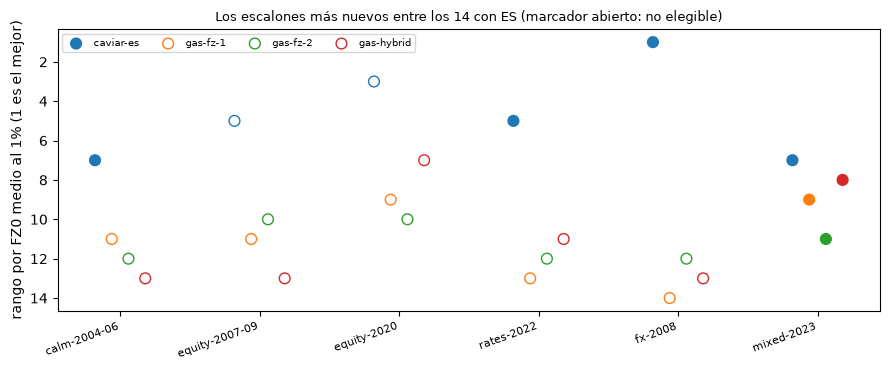

In [4]:
# Dibujar el rango de cada escalón nuevo en cada ventana (1 es el mejor); marcador lleno: modelo elegible,
# abierto: no elegible
eligibility = {w: {m["model_id"]: m["eligible"] for m in docs[w]["outputs"]["models"]} for w in NAMES}
fig, ax = plt.subplots(figsize=(9, 3.8))
for offset, rung in enumerate(newest):
    xs = np.arange(len(NAMES)) + (offset - 1.5) * 0.12
    faces = [f"C{offset}" if eligibility[w][rung] else "none" for w in NAMES]
    ax.scatter(xs, [ranks[w][rung] for w in NAMES], s=60, label=rung, facecolors=faces, edgecolors=f"C{offset}")
ax.invert_yaxis()
ax.set_xticks(range(len(NAMES)), NAMES, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("rango por FZ0 medio al 1% (1 es el mejor)")
ax.set_title("Los escalones más nuevos entre los 14 con ES (marcador abierto: no elegible)", fontsize=9)
ax.legend(fontsize=7, ncol=4)
fig.tight_layout()
plt.show()

Cada marcador es el rango de uno de los cuatro escalones más nuevos entre los 14 con ES en una ventana, al 1 por ciento, y una posición baja en el gráfico significa una pérdida baja. `caviar-es` queda entre 1 y 7 en todas las ventanas y es primero en `fx-2008`, donde es el campeón; los tres escalones GAS-FZ quedan entre 7 y 14 en todas partes, y ninguno llega a los seis primeros lugares de ninguna ventana. El mejor escalón cambia con la ventana: `gjr-t` en tres de ellas, `fhs` en `equity-2020`, `ewma` en `rates-2022` y `caviar-es` en `fx-2008`. Un marcador abierto es un modelo que las compuertas retiraron, de modo que un rango bajo en un marcador abierto no es un campeón. La figura ordena y no prueba: cuán lejos están dos rangos en pérdida es la pregunta del paso siguiente.

### Paso 2: probar la diferencia, Diebold-Mariano frente a dos referencias clásicas

Un rango no es una prueba. Donde las pérdidas realizadas están versionadas podemos probar la diferencia de FZ0 medio entre un escalón nuevo y una referencia clásica con `diebold_mariano` (pronósticos a un paso, sin rezagos). Las referencias son `ewma` (el modelo simple de volatilidad) y `evt-mf` (el escalón de EVT condicional); un estadístico positivo significa que el escalón nuevo tiene la mayor pérdida. La celda contrasta los cuatro escalones nuevos contra ambas referencias al 1 y al 2,5 por ciento en `fx-2008` y `rates-2022` y cuenta los resultados; la figura que sigue dibuja los 32 estadísticos.

In [5]:
# Diebold-Mariano de los cuatro escalones nuevos contra ewma y evt-mf en la pérdida FZ0, en las ventanas con
# pérdidas realizadas
from riskvalidation.market.scoring import diebold_mariano

references = ("ewma", "evt-mf")
cases = [(w, a) for w in ("fx-2008", "rates-2022") for a in (0.01, 0.025)]
pairs = [(rung, reference) for rung in newest for reference in references]
statistic, pvalue = np.zeros((len(pairs), len(cases))), np.ones((len(pairs), len(cases)))
for j, (window, alpha) in enumerate(cases):
    out = docs[window]["outputs"]
    y = -np.array(out["grid"]["realised_loss"]["loss"])
    levels = {m["model_id"]: [lv for lv in m["by_level"] if lv["alpha"] == alpha][0] for m in out["models"]}
    forecasts = {m: (-np.array(levels[m]["var"]), -np.array(levels[m]["es"])) for m in (*newest, *references)}
    loss_of = {m: fz0_loss(y, v, e, alpha) for m, (v, e) in forecasts.items()}
    for i, (rung, reference) in enumerate(pairs):
        result = diebold_mariano(loss_of[rung], loss_of[reference], 0)
        statistic[i, j], pvalue[i, j] = result.statistic, result.p_value
print(f"caviar-es: {(pvalue[:2] >= 0.05).sum()} de {pvalue[:2].size} comparaciones indistinguibles")
print(f"GAS-FZ: {(statistic[2:] > 0).sum()} de {statistic[2:].size} con la mayor pérdida, "
      f"{((statistic[2:] > 0) & (pvalue[2:] < 0.05)).sum()} significativas")
print(f"nuevos significativamente mejores: {((statistic < 0) & (pvalue < 0.05)).sum()}")

caviar-es: 8 de 8 comparaciones indistinguibles
GAS-FZ: 24 de 24 con la mayor pérdida, 12 significativas
nuevos significativamente mejores: 0


La figura dibuja los 32 estadísticos de Diebold-Mariano, una fila por cada escalón nuevo y referencia y una columna por cada ventana y nivel; una estrella marca un valor p bajo 0,05 y el rojo significa que el escalón nuevo tiene la mayor pérdida.

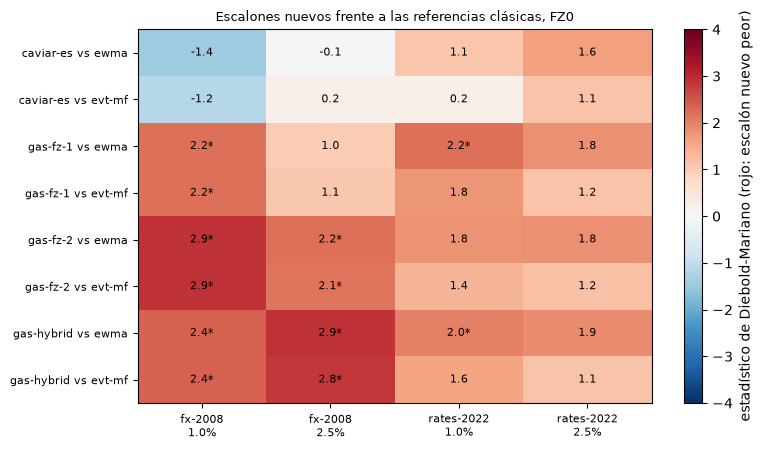

In [6]:
# Dibujar los estadísticos de Diebold-Mariano de los escalones nuevos contra las dos referencias (una
# estrella marca p < 0,05)
labels = [f"{rung} vs {reference}" for rung, reference in pairs]
fig, ax = plt.subplots(figsize=(8, 4.6))
image = ax.imshow(statistic, cmap="RdBu_r", vmin=-4, vmax=4, aspect="auto")
ax.set_xticks(range(len(cases)), [f"{w}\n{a:.1%}" for w, a in cases], fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(cases)):
        text = f"{statistic[i, j]:.1f}" + ("*" if pvalue[i, j] < 0.05 else "")
        ax.text(j, i, text, ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="estadístico de Diebold-Mariano (rojo: escalón nuevo peor)")
ax.set_title("Escalones nuevos frente a las referencias clásicas, FZ0", fontsize=9)
fig.tight_layout()
plt.show()

Las celdas rojas son comparaciones en que el escalón nuevo tiene una pérdida mayor que la referencia y las azules lo contrario. `caviar-es` tiene estadísticos entre -1,4 y 1,6 y ninguna estrella: no se distingue de `ewma` ni de `evt-mf` en ninguna de las 8 comparaciones. Los tres escalones GAS-FZ tienen un estadístico positivo en las 24 comparaciones y 12 de ellas llevan estrella: las seis de `fx-2008` al 1 por ciento, cuatro al 2,5 por ciento (`gas-fz-2` y `gas-hybrid`) y dos en `rates-2022` al 1 por ciento contra `ewma`. Ninguna celda es azul con estrella, de modo que ningún escalón nuevo es significativamente mejor que uno clásico. La figura muestra la dirección y la fuerza de cada comparación; no muestra por qué pierden los escalones GAS-FZ, y el registro de sus ajustes en la última figura es el primer lugar donde mirar.

## Estado del arte

Los métodos de abajo son la frontera académica actual para pronosticar VaR y ES conjuntamente, con su situación en la escalera.

| Método | Qué modela | En la escalera | Fuente |
|---|---|---|---|
| **GAS-FZ, un factor** | el VaR y la ES como $v_t = a\,e^{\kappa_t}$, $e_t = b\,e^{\kappa_t}$ con $\kappa_{t+1} = \beta\kappa_t + \gamma\,(-1/e_t)\big(\tfrac1\alpha \mathbb 1\{y_t \le v_t\}y_t - e_t\big)$, estimado minimizando la pérdida FZ0 promedio | `gas-fz-1`, escalón R9 | Patton, Ziegel y Chen (2019) |
| **GAS-FZ, dos factores** | $(v, e)_{t+1} = w + B\,(v, e)_t + A\,(\lambda_v, \lambda_e)_t$, una recursión impulsada por el score con un factor propio por medida | `gas-fz-2`, escalón R9 | Patton, Ziegel y Chen (2019) |
| **GARCH-FZ híbrido** | el modelo de un factor más un término $\delta\ln\lvert y_t\rvert$ agregado a la recursión del factor | `gas-hybrid`, escalón R9 | Patton, Ziegel y Chen (2019), ecuación 27 |
| **CAViaR-ES** | el VaR sigue una recursión CAViaR; la ES es el VaR menos una brecha autorregresiva, por verosimilitud Laplace asimétrica | `caviar-es`, escalón R8, estimado en **dos pasos** (el motor declara esto como su desviación respecto de la estimación conjunta de Taylor) | Taylor (2019) |
| **Modelos de cuantiles y de cuantiles neuronales sobre la pérdida FZ** | cuantiles de retorno y ES desde una red entrenada con FZ0; una línea activa de preprints | `nn-fz`, escalón R10, **no ejecutado** | preprints recientes (por ejemplo arXiv 2606.04576) |
| **Prueba retrospectiva comparativa** | el marco del paso 1: H0 es que el modelo interno no es peor que uno estándar, bajo una pérdida consistente | la comparación del notebook 05 | Nolde y Ziegel (2017) |
| **Pruebas retrospectivas multinomiales de VaR** | varios niveles de VaR a la vez como una prueba retrospectiva implícita de ES | **no está en el motor** | Kratz, Lok y McNeil (2018) |

La situación honesta de la línea neuronal, a la fecha de la investigación detrás de este producto, es que ningún regulador la reconoce como estándar para modelos internos y sus ganancias sobre un referente GARCH, EVT o GAS-FZ bien especificado dependen del conjunto de datos. Contraste la trata por eso solo como retador: tendría que entrar al conjunto de confianza de 90 por ciento en FZ0 **fuera de muestra**, mostrado por Diebold-Mariano y el conjunto de confianza y no por ajuste dentro de muestra. El documento de la escalera registra que `nn-fz` no se entrenó; nada en los datos versionados evalúa un modelo neuronal, y este notebook no afirma que uno lo haría mejor o peor.

Las celdas siguientes corren el conjunto de confianza de modelos sobre la escalera, ajustan el GARCH-t del producto frente a la referencia `arch` y dibujan el registro versionado de cómo se comportaron los ajustes más nuevos.

conjunto: 13 de 14
fuera del conjunto: ['dn-rolling']
caviar-es   valor p de MCS 1.000
gas-fz-1    valor p de MCS 0.678
gas-fz-2    valor p de MCS 0.493
gas-hybrid  valor p de MCS 0.644


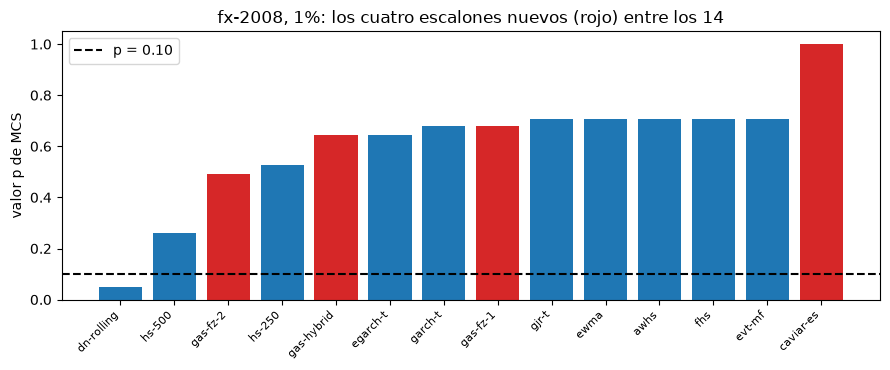

In [7]:
# Conjunto de confianza de modelos de los 14 escalones con ES en fx-2008 al 1% con la pérdida FZ0, y el
# valor p de cada escalón dibujado
from riskvalidation.market.scoring import model_confidence_set

fx = docs["fx-2008"]["outputs"]
y = -np.array(fx["grid"]["realised_loss"]["loss"])
setting = [m for m in fx["comparison"]["mcs"] if m["alpha"] == 0.01][0]
ids = [m["model_id"] for m in setting["members"]]
levels = {m["model_id"]: m["by_level"][0] for m in fx["models"]}
losses = np.column_stack([fz0_loss(y, -np.array(levels[i]["var"]), -np.array(levels[i]["es"]), 0.01) for i in ids])
args = (setting["confidence"], setting["statistic"], setting["n_bootstrap"], setting["block_length"], 42)
mcs = model_confidence_set(losses, *args)
print(f"conjunto: {len(mcs.members)} de {len(ids)}")
print("fuera del conjunto:", [ids[i] for i in range(len(ids)) if i not in mcs.members])
for rung in newest:
    print(f"{rung:11s} valor p de MCS {mcs.p_values[ids.index(rung)]:.3f}")

order = np.argsort(mcs.p_values)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(len(ids)), mcs.p_values[order], color=["tab:red" if ids[i] in newest else "tab:blue" for i in order])
ax.axhline(0.10, color="black", linestyle="--", label="p = 0.10")
ax.set_xticks(range(len(ids)), [ids[i] for i in order], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("valor p de MCS")
ax.set_title("fx-2008, 1%: los cuatro escalones nuevos (rojo) entre los 14")
ax.legend()
fig.tight_layout()
plt.show()

Cada barra es el valor p de MCS de un escalón en `fx-2008` al 1 por ciento, y un escalón está en el conjunto de 90 por ciento cuando su barra supera la línea de trazos de 0,10. Trece de los 14 escalones están en el conjunto y solo `dn-rolling` queda fuera. Los cuatro más nuevos (barras rojas) están todos dentro: `caviar-es` con p de 1,000 como la menor pérdida, `gas-fz-1` con 0,678, `gas-hybrid` con 0,644 y `gas-fz-2` con 0,493. El conjunto y las pruebas de a pares del paso 2 dan respuestas distintas a preguntas distintas: el conjunto pregunta qué escalones no se pueden excluir frente a toda la escalera, con un remuestreo sobre el rango de las pérdidas, y tiene menos potencia que una prueba de a pares contra una referencia. La figura muestra que los datos de un año no pueden excluir a los escalones GAS-FZ del conjunto, aunque dos referencias los superen uno a uno.

### Paso 3: el ajuste GARCH-t del motor frente a la referencia `arch`

El escalón GARCH del producto es un ajuste de cuasi máxima verosimilitud de un GARCH(1,1) con innovaciones t de Student y media constante, y el motor lo corre mediante el paquete `arch` (`riskvalidation.market.garch.fit_garch`). Eso tiene una consecuencia que hay que decir primero: `arch` es la referencia de las propias pruebas del motor y no una reimplementación independiente, así que esta verificación no puede encontrar un error dentro de `arch`. Verifica lo que el motor agrega alrededor de la llamada: el escalado de los retornos a porcentaje y de vuelta a decimales, el desplazamiento de la log-verosimilitud en $n \ln 100$, los nombres de los parámetros y el veredicto de convergencia. Dos celdas ajustan los mismos retornos versionados de tres maneras: con el motor; con una llamada directa a `arch.arch_model` en porcentaje cuyos parámetros se devuelven a decimales; y con `arch` otra vez desde un punto de partida distinto, lo que prueba que el óptimo pertenece a la verosimilitud y no al punto de partida.

Los datos de entrada son los 251 retornos realizados que versiona `fx-2008` (un retorno es la pérdida con el signo cambiado). El motor necesita al menos 250 retornos para ajustar, y `rates-2022` versiona 249, así que la segunda celda muestra también el rechazo de esa serie por el motor. Las tolerancias se declaran antes de la corrida. Motor frente a la llamada directa a `arch`: diferencia relativa bajo $10^{-9}$ (mismo optimizador y mismo punto de partida, de modo que solo el orden de las operaciones de coma flotante puede diferir). `arch` desde el segundo punto de partida: log-verosimilitud dentro de $10^{-6}$ y parámetros dentro de $10^{-3}$ relativo (el optimizador se detiene en una tolerancia, y una verosimilitud GARCH es plana cerca de su óptimo).

In [8]:
# Ajustar el GARCH-t del motor y la referencia arch sobre los 251 retornos realizados versionados de fx-2008
import arch
from riskvalidation.market import garch

returns = y
engine_fit = garch.fit_garch(returns, "garch", "student-t", "constant")
model = arch.arch_model(returns * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="t", rescale=False)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    reference = model.fit(disp="off", show_warning=False, update_freq=0)
scale = {"mu": 100, "omega": 100 ** 2, "alpha[1]": 1, "beta[1]": 1, "nu": 1}
print(f"{'parámetro':10s} {'motor':>14s} {'arch':>14s} {'diferencia relativa':>22s}")
for name, factor in scale.items():
    value = reference.params[name] / factor
    relative = abs(engine_fit.params[name] / value - 1)
    print(f"{name:10s} {engine_fit.params[name]:14.8g} {value:14.8g} {relative:22.2e}")
arch_ll = reference.loglikelihood + len(returns) * math.log(100)
print(f"log-verosimilitud: motor {engine_fit.log_likelihood:.6f} | arch {arch_ll:.6f}")
print(f"el motor convergió: {'sí' if engine_fit.converged else 'no'} | bandera de arch {reference.convergence_flag}")

parámetro           motor           arch    diferencia relativa
mu         -0.00075822796 -0.00075822796               0.00e+00
omega       1.8944118e-06  1.8944118e-06               0.00e+00
alpha[1]      0.044303998    0.044303998               0.00e+00
beta[1]        0.94373067     0.94373067               0.00e+00
nu              5.2144163      5.2144163               0.00e+00
log-verosimilitud: motor 803.654204 | arch 803.654204
el motor convergió: sí | bandera de arch 0


La segunda celda reajusta `arch` desde un segundo punto de partida fijo, que caería en un óptimo distinto si la verosimilitud tuviera varios, y muestra que el motor rechaza los 249 retornos de `rates-2022`.

In [9]:
# Reajustar arch desde un segundo punto de partida fijo y mostrar el rechazo de los 249 retornos de
# rates-2022 por el motor
second_start = np.array([0.0, 0.05, 0.10, 0.80, 8.0])
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    second = model.fit(disp="off", show_warning=False, update_freq=0, starting_values=second_start)
relative = {name: abs(second.params[name] / reference.params[name] - 1) for name in scale}
print(f"segundo punto de partida: mayor diferencia relativa en un parámetro {max(relative.values()):.2e}")
print(f"diferencia de log-verosimilitud {abs(second.loglikelihood - reference.loglikelihood):.2e}")

rates = -np.array(docs["rates-2022"]["outputs"]["grid"]["realised_loss"]["loss"])
try:
    garch.fit_garch(rates, "garch", "student-t", "constant")
except ValueError:
    print(f"rates-2022: {rates.size} retornos, el motor rechaza la serie (mínimo 250)")

segundo punto de partida: mayor diferencia relativa en un parámetro 1.15e-04
diferencia de log-verosimilitud 8.26e-08
rates-2022: 249 retornos, el motor rechaza la serie (mínimo 250)


El motor y la llamada directa a `arch` devuelven los mismos cinco parámetros, con una diferencia relativa de 0,00e+00 en cada uno, y la misma log-verosimilitud, 803,654204; el motor informa convergencia y `arch` devuelve la bandera 0. Los grados de libertad ajustados de 5,2144163 describen colas pesadas, y la persistencia $\alpha_1 + \beta_1$ es cercana a 0,99. `arch` desde un segundo punto de partida llega a una log-verosimilitud a 8,26e-08 y a parámetros dentro de 1,15e-04 relativo, dentro de las tolerancias declaradas antes de la corrida. El motor llama a `arch`, así que la verificación confirma su envoltura (el escalado a porcentaje y de vuelta, el desplazamiento de la log-verosimilitud, los nombres de los parámetros) y que el óptimo no depende del punto de partida; no prueba `arch` mismo. `rates-2022` versiona 249 retornos, uno menos que el mínimo de 250 del motor, de modo que el motor lo rechaza. La última figura dibuja el registro versionado de con qué frecuencia no convergieron los ajustes más nuevos.

garch-t     todas las ventanas 13.4%
caviar-es   todas las ventanas 0.1%
gas-fz-1    todas las ventanas 3.5%
gas-fz-2    todas las ventanas 47.2%
gas-hybrid  todas las ventanas 10.4%


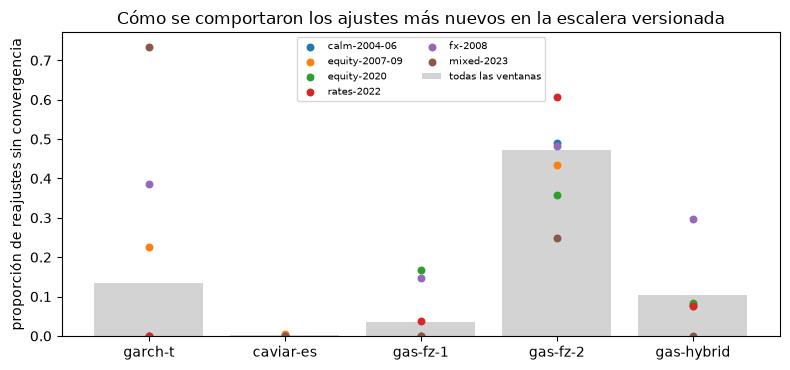

In [10]:
# La proporción versionada de reajustes que no convergieron, por escalón y ventana, para los escalones
# nuevos y GARCH-t
fits = {e["model_id"]: {wf["window_id"]: wf for wf in e["window_fits"]} for e in ladder if e["window_fits"]}
rungs = ("garch-t", "caviar-es", "gas-fz-1", "gas-fz-2", "gas-hybrid")
share = {m: [fits[m][w]["n_convergence_failures"] / fits[m][w]["n_refits"] for w in NAMES] for m in rungs}
failures = {m: sum(fits[m][w]["n_convergence_failures"] for w in NAMES) for m in rungs}
total = {m: failures[m] / sum(fits[m][w]["n_refits"] for w in NAMES) for m in rungs}
for m in rungs:
    print(f"{m:11s} todas las ventanas {total[m]:.1%}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(range(len(rungs)), [total[m] for m in rungs], color="lightgrey", label="todas las ventanas")
for k, w in enumerate(NAMES):
    ax.scatter(range(len(rungs)), [share[m][k] for m in rungs], s=22, label=w)
ax.set_xticks(range(len(rungs)), rungs)
ax.set_ylabel("proporción de reajustes sin convergencia")
ax.set_title("Cómo se comportaron los ajustes más nuevos en la escalera versionada")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

Las barras grises son la proporción de reajustes que no convergieron en las seis ventanas y los puntos son la proporción en cada ventana. El GAS-FZ de dos factores falló en 47,2 por ciento de sus reajustes, el híbrido en 10,4 por ciento y el de un factor en 3,5 por ciento, mientras que `caviar-es` falló en 0,1 por ciento. Para comparar, GARCH-t, que el motor ajusta mediante `arch`, falló en 13,4 por ciento, concentrado en `mixed-2023` y `fx-2008`. El registro no dice cómo trató el proceso un reajuste fallido, solo que el modelo de dos factores es el menos confiable de ajustar; es el mismo escalón que pierde con más claridad en las comparaciones de arriba. La figura apoya leer los resultados de GAS-FZ como evidencia sobre el estimador tal como se corrió aquí, con 20 puntos de partida y un reajuste cada 20 días, y no sobre la clase de modelo.

### La red de cuantiles entrenada con FZ0, corrida sobre una verdad conocida (M-30)

Los retadores neuronales de la literatura (la línea de trabajo posterior a Patton, Ziegel y Chen 2019) entrenan una red para
entregar directamente el VaR y el ES, minimizando la pérdida FZ0, que es estrictamente consistente para el par. El peldaño R10 del
producto es la forma compacta de esa idea (`pipeline.cases.c11.quantile_net`): para cada día los cinco retornos anteriores y sus
valores absolutos divididos por la volatilidad RiskMetrics, y el logaritmo del cociente entre una volatilidad rápida y una lenta,
alimentan una capa oculta de 8 unidades con dos salidas softplus, el VaR y la distancia del ES bajo él; la red minimiza la FZ0 media
de los retornos estandarizados en la ventana de 1.000 días anterior a cada pronóstico, se reajusta cada 20 días y conserva el mejor
de tres arranques con semilla. Su configuración se fijó con 1995 a 2003, como la de todos los demás peldaños.

Los retornos de la mayoría de las ventanas de C11 son solo derivados y no están en el repositorio, así que este notebook mide el
peldaño donde la respuesta se conoce: un GARCH(1,1) con shocks t de Student, cuyos VaR y ES se conocen cada día. La red y dos
peldaños del motor, GARCH-t (el modelo que generó los datos) y EWMA, corren sobre las mismas ventanas de 1.000 días durante los
últimos 250 días.

In [ ]:
# Sortear 1.250 días de un GARCH(1,1) con shocks t de Student de varianza unitaria, de VaR y ES al 2,5% conocidos
from scipy import stats

OMEGA, A1, B1, NU, ALPHA = 2e-6, 0.08, 0.90, 5.0, 0.025
n_days, window = 1250, 1000
rng = np.random.default_rng(20261030)
scale = np.sqrt((NU - 2) / NU)
shock = rng.standard_t(NU, n_days) * scale
sig2 = np.empty(n_days)
y = np.empty(n_days)
sig2[0] = OMEGA / (1 - A1 - B1)
for t in range(n_days):
    if t:
        sig2[t] = OMEGA + A1 * y[t - 1] ** 2 + B1 * sig2[t - 1]
    y[t] = np.sqrt(sig2[t]) * shock[t]
q = stats.t.ppf(ALPHA, NU)
var_unit = q * scale
es_unit = -stats.t.pdf(q, NU) / ALPHA * (NU + q * q) / (NU - 1) * scale
true_v = np.sqrt(sig2[window:]) * var_unit
true_e = np.sqrt(sig2[window:]) * es_unit
out = y[window:]
unit_label = "cuantil y pérdida esperada de varianza unitaria"
days_label = "días de pronóstico"
print(f"{unit_label}: VaR {var_unit:.4f}, ES {es_unit:.4f} | {days_label}: {out.size}")


El cuantil de varianza unitaria al 2,5 % de una t de Student con 5 grados de libertad es -1,99, cercano al -1,96 normal,
pero su pérdida esperada es más gruesa que la normal. La celda siguiente pronostica cada uno de los últimos 250 días desde los 1.000
días anteriores: la red se reajusta cada 20 días, como en el producto, y también GARCH-t, mientras EWMA se actualiza cada día; cada
pronóstico se evalúa contra el retorno realizado con la pérdida FZ0 del motor, y contra el VaR verdadero.

In [ ]:
# Pronosticar los 250 días con la red del peldaño R10, el GARCH-t del motor y EWMA, cada uno con 1.000 días
from riskvalidation.market import garch, parametric
from riskvalidation.market.scoring import fz0_loss

from pipeline.cases.c11 import quantile_net as qn

rows = {"nn-fz (R10)": ([], []), "garch-t": ([], []), "ewma": ([], [])}
for i in range(window, n_days):
    win = y[i - window:i]
    if (i - window) % qn.NET.refit_every_days == 0:
        fit_nn = qn.fit_net(win, ALPHA, qn.NET, seed=11)
        fit_g = garch.fit_garch(win, "garch", "student-t", "constant")
    forecasts = (qn.predict(fit_nn, win), garch.garch_var_es_forecast(fit_g, win, ALPHA),
                 parametric.ewma_var_es(win, 0.94, ALPHA, float(np.var(win[:20]))))
    for name, (v, e) in zip(rows, forecasts):
        rows[name][0].append(v)
        rows[name][1].append(e)
truth_fz0 = np.mean(fz0_loss(out, true_v, true_e, ALPHA))
truth_label = "verdad"
exc_label = "excesos"
gap_label = "media de |VaR / VaR verdadero - 1|"
print(f"{truth_label:14s} {exc_label} {int((out < true_v).sum()):3d} | FZ0 {truth_fz0:.4f}")
for name, (v, e) in rows.items():
    v, e = np.array(v), np.array(e)
    gap = np.mean(np.abs(v / true_v - 1))
    score = np.mean(fz0_loss(out, v, e, ALPHA))
    print(f"{name:14s} {exc_label} {int((out < v).sum()):3d} | FZ0 {score:.4f} | {gap_label} {gap:.3f}")


El VaR verdadero se excede 4 veces en 250 días contra 6,25 esperadas, el ruido muestral de un año. GARCH-t, el modelo que
sorteó los datos, tiene los mismos 4 excesos y un VaR a 3,8 % de la verdad en promedio; EWMA queda a 7,4 %. La red se excede 25
veces y su VaR es 39,7 % demasiado pequeño en promedio, así que su FZ0 media, 0,0587, queda muy por encima del -3,88 de GARCH-t y
del -3,90 de la verdad: la pérdida castiga un VaR demasiado cercano a cero. La figura muestra de dónde viene la brecha.

In [ ]:
# Dibujar los 250 días de pronóstico: los retornos, el VaR verdadero y el VaR de la red y del GARCH-t
days = np.arange(out.size)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(days, 100 * out, color="lightgrey", linewidth=0.8, label="retorno diario")
ax.plot(days, 100 * true_v, color="black", label="VaR verdadero al 2,5%")
ax.plot(days, 100 * np.array(rows["nn-fz (R10)"][0]), color="tab:red", label="nn-fz (R10)")
ax.plot(days, 100 * np.array(rows["garch-t"][0]), "--", color="tab:blue", label="garch-t")
ax.set_xlabel("día de pronóstico")
ax.set_ylabel("por ciento del valor")
ax.set_title("VaR a un día al 2,5% sobre un GARCH-t conocido")
ax.legend(fontsize=8, ncol=4)
fig.tight_layout()
plt.show()


El VaR de la red sigue a la volatilidad, así que su momento es correcto: se abre y se cierra con el VaR verdadero. Su nivel
está equivocado, una banda cerca de un tercio más estrecha que la verdad, y se excede en la mayoría de los días en que el VaR
verdadero casi lo es. Con 1.000 días y una cola de 2,5 % la red ve unas 25 observaciones de cola por ajuste; el gradiente de FZ0
viene casi todo de ellas, y ocho unidades ocultas ajustadas a tan pocos puntos aprenden el cuerpo de la distribución mejor que su
cola. GARCH-t tiene la familia paramétrica correcta y no necesita observaciones de cola para fijar su cuantil. La corrida del
producto sobre las ventanas reales muestra el mismo comportamiento.

In [ ]:
# La corrida del propio producto de R10: su elegibilidad y el campeón al 2,5% en cada una de las seis ventanas
eligible_label = "elegible"
hits_label = "excesos al 1% / esperados"
champion_label = "campeón al 2,5%"
for w in NAMES:
    o = docs[w]["outputs"]
    nn = next(m for m in o["models"] if m["model_id"] == "nn-fz")
    champion = next((c for c in o["comparison"]["champions"] if c["alpha"] == ALPHA), {}).get("model_id")
    level = next(lv for lv in nn["by_level"] if lv["alpha"] == 0.01)
    hits = f"{level['n_exceedances']} / {level['expected_exceedances']:.1f}"
    flag = str(nn["eligible"])
    print(f"{w:15s} R10 {eligible_label} {flag:5s} | {hits_label} {hits:9s} | {champion_label} {champion}")


En las seis ventanas del producto la red pasa todas las compuertas de elegibilidad solo en fx-2008 y mixed-2023 y no es
campeona en ninguna: se excede 22 veces al 1 % en la ventana tranquila donde se esperan 7,5, la misma cola estrecha que mostró la
verdad conocida, y los campeones son EWMA, EVT y GJR-t. S-1 replicó el estado del arte como pedía el plan (entrenado, filtrado y
ordenado como cualquier otro peldaño) e informa que, con este tamaño, no supera a los peldaños econométricos; una red mayor o una
ventana más larga es un cambio de método que habría que fijar antes de las ventanas de prueba, no ajustar sobre ellas.

## Resultados

**Respuesta:** No. En seis ventanas los escalones más nuevos no se ubican de forma consistente sobre los clásicos: `caviar-es` es indistinguible de `ewma` y de `evt-mf` en 8 de 8 comparaciones, y los tres escalones GAS-FZ tienen la mayor pérdida en 24 de 24 comparaciones, 12 de ellas significativas y ninguna significativamente mejor, sin ningún escalón GAS-FZ entre los seis primeros de ninguna ventana. El ajuste GARCH-t del motor es igual a la referencia `arch` en `fx-2008` (log-verosimilitud 803,654204 en ambos, una diferencia relativa de 0,00e+00 en cada parámetro), lo que verifica la envoltura del motor y no `arch` mismo.

- **Rangos.** Entre los 14 escalones con ES, al 1 por ciento, `caviar-es` queda 7, 5, 3, 5, 1 y 7 en las seis ventanas (primero en `fx-2008`); `gas-fz-1` queda 11, 11, 9, 13, 14 y 9; `gas-fz-2` 12, 10, 10, 12, 12 y 11; `gas-hybrid` 13, 13, 7, 11, 13 y 8. El mejor escalón es `gjr-t` en tres ventanas, `fhs` en `equity-2020`, `ewma` en `rates-2022` y `caviar-es` en `fx-2008`.
- **Las pruebas concuerdan con los rangos.** De las 24 comparaciones de los escalones GAS-FZ con las dos referencias, 24 tienen la mayor pérdida y 12 son significativas al 5 por ciento; 0 escalones nuevos son significativamente mejores.
- **El conjunto de confianza.** Al 1 por ciento en `fx-2008` el conjunto tiene 13 de 14 escalones y excluye solo a `dn-rolling`; los cuatro más nuevos están dentro, con valores p de MCS de 1,000 (`caviar-es`), 0,678, 0,493 y 0,644.
- **Cómo se comportaron los ajustes.** En las seis ventanas 47,2 por ciento de los reajustes de `gas-fz-2` no convergió, 10,4 por ciento de `gas-hybrid`, 3,5 por ciento de `gas-fz-1` y 0,1 por ciento de `caviar-es`; GARCH-t falló en 13,4 por ciento.
- **El ajuste GARCH-t frente a `arch`.** El motor y `arch` devuelven los mismos cinco parámetros y la log-verosimilitud 803,654204; desde un segundo punto de partida `arch` queda a 8,26e-08 en log-verosimilitud y a 1,15e-04 relativo en los parámetros, dentro de las tolerancias declaradas. `rates-2022` versiona 249 retornos, uno menos que el mínimo de 250 del motor.
- **Qué apoya la evidencia.** En estas ventanas, con los ajustes de estimación del producto, los escalones semiparamétricos dinámicos no superaron a los clásicos y CAViaR-ES los igualó. La evidencia son seis ventanas en dos niveles con 64 a 750 días; no apoya una afirmación sobre esos métodos en general, y es muda sobre un modelo neuronal, que no se ejecutó.

Lo que este notebook no muestra: ningún componente nuevo de Contraste más allá de esta práctica; esos están en los notebooks de nivel 4 de los temas que llevan una afirmación.

La red de cuantiles entrenada con FZ0 (M-30, peldaño R10) no supera a los peldaños econométricos: sobre un GARCH-t conocido
se excede 25 veces en 250 días contra 6,25 esperadas y su VaR es 39,7 % demasiado pequeño en promedio, mientras GARCH-t queda a
3,8 %; en las seis ventanas del producto es elegible en 2 y campeona en ninguna.

## Resumen

- Los métodos más nuevos para VaR y ES modelan el par conjuntamente y lo dejan evolucionar con los datos: GAS-FZ y su híbrido minimizan la propia pérdida FZ0, CAViaR-ES agrega una ES a una recursión de cuantil, y los modelos neuronales de cuantiles son una línea de preprints.
- El marco de la prueba retrospectiva comparativa pregunta si un retador supera a un modelo estándar bajo una pérdida consistente, no solo si el campeón se rechaza; Contraste lo usa después de que las pruebas retrospectivas tradicionales han decidido la elegibilidad.
- En seis ventanas de mercado versionadas los escalones más nuevos no se ubican de forma consistente sobre los clásicos: Diebold-Mariano no encuentra ningún escalón nuevo significativamente mejor, y los escalones GAS-FZ son los menos estables en el registro de sus ajustes.
- El conjunto de confianza de modelos al 1 por ciento en `fx-2008` mantiene dentro a los cuatro escalones más nuevos, de modo que las pruebas de a pares y el conjunto responden preguntas distintas con los mismos datos.
- El retador neuronal está registrado como no ejecutado, así que la escalera no ofrece evidencia sobre él; tendría que entrar al conjunto de confianza de 90 por ciento fuera de muestra.
- El ajuste GARCH-t del motor es igual a una llamada directa a `arch` sobre los retornos de `fx-2008` versionados en los dígitos impresos y no depende del punto de partida del optimizador; eso verifica la envoltura del motor, no `arch`.

**Qué probar después.** Recalcula la tabla del paso 2 en el otro nivel en `rates-2022` con una referencia distinta y nombra la ventana y el nivel en que un escalón nuevo es significativamente mejor, si existe; luego lee la página del caso de C11 para la escalera completa.

- La red entrenada con FZ0 del peldaño R10 (M-30) sigue a la volatilidad pero subestima la cola: 25 excesos contra 6,25 esperados sobre una verdad conocida, y ninguna ventana ganada con los datos del producto.

## Referencias

- Patton, A. J., Ziegel, J. F. y Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008 (preprint https://arxiv.org/abs/1707.05108)
- Taylor, J. W. (2019), Forecasting value at risk and expected shortfall using a semiparametric approach based on the asymmetric Laplace distribution, Journal of Business and Economic Statistics 37(1). https://doi.org/10.1080/07350015.2017.1281815
- Nolde, N. y Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041
- Kratz, M., Lok, Y. H. y McNeil, A. J. (2018), Multinomial VaR backtests: a simple implicit approach to backtesting expected shortfall, Journal of Banking and Finance 88. https://doi.org/10.1016/j.jbankfin.2018.01.002
- Diebold, F. X. y Mariano, R. S. (1995), Comparing predictive accuracy, Journal of Business and Economic Statistics 13(3). https://doi.org/10.1080/07350015.1995.10524599
- Hansen, P. R., Lunde, A. y Nason, J. M. (2011), The model confidence set, Econometrica 79(2). https://doi.org/10.3982/ECTA5771
- Una red neuronal conjunta de VaR y ES entrenada con la pérdida FZ (preprint, solo retador). https://arxiv.org/abs/2606.04576